#### Imports


In [1]:
from pathlib import Path
import json
import numpy as np
import tensorflow as tf
import pandas as pd
import random
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Full data loader

In [2]:
dataset_dirs = {
    "phone": Path("har_stage2_production_phones_v1"),
    "watch": Path("har_stage2_production_watch_v1"),
}

class_names = [
    "bike",
    "sit",
    "stairsdown",
    "stairsup",
    "stand",
    "walk"
]

label_to_index = {
    "bike": 0,
    "sit": 1,
    "stairsdown": 2,
    "stairsup": 3,
    "stand": 4,
    "walk": 5
}

all_X = []
all_y = []
all_participants = []
all_sources = []
all_metadata = []


for source_name, dataset_dir in dataset_dirs.items():
    print(f"\nLoading {source_name}: {dataset_dir}")

    shard_paths = sorted(dataset_dir.glob("windows-*.npz"))
    print("Shards found:", len(shard_paths))

    source_X = []
    source_y = []
    source_participants = []

    for shard_path in shard_paths:
        with np.load(shard_path, allow_pickle=False) as z:
            X = z["X"].astype(np.float32)
            labels = z["labels"]
            metadata = z["metadata"]

            y = np.array([
                label_to_index[str(label)]
                for label in labels
            ], dtype=np.int64)

            participants = np.array([
                json.loads(item)["User"]
                for item in metadata
            ])
            
            all_metadata.extend(metadata)

        source_X.append(X)
        source_y.append(y)
        source_participants.append(participants)

    X_source = np.concatenate(source_X, axis=0)
    y_source = np.concatenate(source_y, axis=0)
    participants_source = np.concatenate(source_participants, axis=0)

    print("Windows:", X_source.shape[0])
    print("X shape:", X_source.shape)
    print("Participants:", np.unique(participants_source))

    all_X.append(X_source)
    all_y.append(y_source)
    all_participants.append(participants_source)
    all_sources.append(
        np.full(len(X_source), source_name, dtype="<U16")
    )

X = np.concatenate(all_X, axis=0)
y = np.concatenate(all_y, axis=0)
participant_ids = np.concatenate(all_participants, axis=0)
source_ids = np.concatenate(all_sources, axis=0)
metadata = np.array(all_metadata)

print("\nCombined dataset")
print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)
print("Participants:", np.unique(participant_ids))
print("Sources:", np.unique(source_ids))
print("Windows per source:")

print("Metadata records:", len(metadata))
print("Windows:", len(X))

assert len(metadata) == len(X)

for source in np.unique(source_ids):
    print(f"{source}: {np.sum(source_ids == source)}")


Loading phone: har_stage2_production_phones_v1
Shards found: 58
Windows: 32160
X shape: (32160, 128, 6)
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']

Loading watch: har_stage2_production_watch_v1
Shards found: 25
Windows: 5032
X shape: (5032, 128, 6)
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']

Combined dataset
X: (37192, 128, 6) float32
y: (37192,) int64
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']
Sources: ['phone' 'watch']
Windows per source:
Metadata records: 37192
Windows: 37192
phone: 32160
watch: 5032


#### To see specific devices

In [3]:
device_ids = np.array([
    json.loads(item)["Device"]
    for item in metadata
])

print("device_ids shape:", device_ids.shape)
print("Unique devices:", np.unique(device_ids))

assert device_ids.shape[0] == X.shape[0]

device_ids shape: (37192,)
Unique devices: ['gear_1' 'gear_2' 'lgwatch_1' 'lgwatch_2' 'nexus4_1' 'nexus4_2' 's3_1'
 's3_2' 's3mini_1' 's3mini_2']


In [4]:
assert X.ndim == 3
assert X.shape[1:] == (128, 6)
assert X.dtype == np.float32

assert y.ndim == 1
assert len(y) == len(X)
assert len(participant_ids) == len(X)
assert len(source_ids) == len(X)

assert set(np.unique(y)) == set(range(6))
assert set(np.unique(source_ids)) == {"phone", "watch"}

In [5]:
phone_count = int(np.sum(source_ids == "phone"))
watch_count = int(np.sum(source_ids == "watch"))

print(f"Phone windows: {phone_count}")
print(f"Watch windows: {watch_count}")
print(f"Total windows: {len(X)}")

assert phone_count == 32160, (
    f"Expected 32160 phone windows, got {phone_count}"
)

assert watch_count == 5032, (
    f"Expected 5032 watch windows, got {watch_count}"
)

assert len(X) == 37192, (
    f"Expected 37192 total windows, got {len(X)}"
)

print("Participants:", np.unique(participant_ids))
print("Sources:", np.unique(source_ids))
print("Phone windows:", phone_count)
print("Watch windows:", watch_count)

Phone windows: 32160
Watch windows: 5032
Total windows: 37192
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']
Sources: ['phone' 'watch']
Phone windows: 32160
Watch windows: 5032


In [6]:
print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)
print("Participants:", np.unique(participant_ids))
print("Sources:", np.unique(source_ids))

print("\nWindows per source:")
for source in np.unique(source_ids):
    print(source, np.sum(source_ids == source))

print("\nWindows per class:")
for index, name in enumerate(class_names):
    print(name, np.sum(y == index))

X: (37192, 128, 6) float32
y: (37192,) int64
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']
Sources: ['phone' 'watch']

Windows per source:
phone 32160
watch 5032

Windows per class:
bike 5494
sit 7330
stairsdown 4784
stairsup 5797
stand 6256
walk 7531


# Split data


In [7]:
import numpy as np
import pandas as pd

# Put participants in a stable order
unique_participants = np.unique(participant_ids)

# Use the next participant as validation:
# test a -> validate b, test b -> validate c, etc.
validation_participant_for = {
    participant: unique_participants[(index + 1) % len(unique_participants)]
    for index, participant in enumerate(unique_participants)
}

fold_results = []

for test_participant in unique_participants:
    validation_participant = validation_participant_for[test_participant]

    test_mask = participant_ids == test_participant
    validation_mask = participant_ids == validation_participant
    train_mask = (
        (participant_ids != test_participant)
        & (participant_ids != validation_participant)
    )

    train_idx = np.where(train_mask)[0]
    val_idx = np.where(validation_mask)[0]
    test_idx = np.where(test_mask)[0]

    print(
        f"\nFold: test={test_participant}, "
        f"validation={validation_participant}"
    )
    print("Train participants:", np.unique(participant_ids[train_idx]))
    print("Train windows:", len(train_idx))
    print("Validation windows:", len(val_idx))
    print("Test windows:", len(test_idx))

    # Verify participant isolation
    assert test_participant not in participant_ids[train_idx]
    assert validation_participant not in participant_ids[train_idx]
    assert test_participant not in participant_ids[val_idx]
    assert validation_participant not in participant_ids[test_idx]

    # Store the indices for this fold
    fold_results.append({
        "test_participant": test_participant,
        "validation_participant": validation_participant,
        "train_idx": train_idx,
        "val_idx": val_idx,
        "test_idx": test_idx,
    })


Fold: test=a, validation=b
Train participants: ['c' 'd' 'e' 'f' 'g' 'h' 'i']
Train windows: 28444
Validation windows: 4582
Test windows: 4166

Fold: test=b, validation=c
Train participants: ['a' 'd' 'e' 'f' 'g' 'h' 'i']
Train windows: 28661
Validation windows: 3949
Test windows: 4582

Fold: test=c, validation=d
Train participants: ['a' 'b' 'e' 'f' 'g' 'h' 'i']
Train windows: 29057
Validation windows: 4186
Test windows: 3949

Fold: test=d, validation=e
Train participants: ['a' 'b' 'c' 'f' 'g' 'h' 'i']
Train windows: 28272
Validation windows: 4734
Test windows: 4186

Fold: test=e, validation=f
Train participants: ['a' 'b' 'c' 'd' 'g' 'h' 'i']
Train windows: 28654
Validation windows: 3804
Test windows: 4734

Fold: test=f, validation=g
Train participants: ['a' 'b' 'c' 'd' 'e' 'h' 'i']
Train windows: 29573
Validation windows: 3815
Test windows: 3804

Fold: test=g, validation=h
Train participants: ['a' 'b' 'c' 'd' 'e' 'f' 'i']
Train windows: 29348
Validation windows: 4029
Test windows: 3815

#### Verify


In [8]:
for fold in fold_results:
    train_idx = fold["train_idx"]
    val_idx = fold["val_idx"]
    test_idx = fold["test_idx"]

    train_participants = set(np.unique(participant_ids[train_idx]))
    val_participants = set(np.unique(participant_ids[val_idx]))
    test_participants = set(np.unique(participant_ids[test_idx]))

    print(
        f"\nFold: test={fold['test_participant']}, "
        f"validation={fold['validation_participant']}"
    )

    print("Train participants:", sorted(train_participants))
    print("Validation participants:", sorted(val_participants))
    print("Test participants:", sorted(test_participants))

    print("\nTrain windows:", len(train_idx))
    print("Validation windows:", len(val_idx))
    print("Test windows:", len(test_idx))

    assert train_participants.isdisjoint(val_participants)
    assert train_participants.isdisjoint(test_participants)
    assert val_participants.isdisjoint(test_participants)


Fold: test=a, validation=b
Train participants: [np.str_('c'), np.str_('d'), np.str_('e'), np.str_('f'), np.str_('g'), np.str_('h'), np.str_('i')]
Validation participants: [np.str_('b')]
Test participants: [np.str_('a')]

Train windows: 28444
Validation windows: 4582
Test windows: 4166

Fold: test=b, validation=c
Train participants: [np.str_('a'), np.str_('d'), np.str_('e'), np.str_('f'), np.str_('g'), np.str_('h'), np.str_('i')]
Validation participants: [np.str_('c')]
Test participants: [np.str_('b')]

Train windows: 28661
Validation windows: 3949
Test windows: 4582

Fold: test=c, validation=d
Train participants: [np.str_('a'), np.str_('b'), np.str_('e'), np.str_('f'), np.str_('g'), np.str_('h'), np.str_('i')]
Validation participants: [np.str_('d')]
Test participants: [np.str_('c')]

Train windows: 29057
Validation windows: 4186
Test windows: 3949

Fold: test=d, validation=e
Train participants: [np.str_('a'), np.str_('b'), np.str_('c'), np.str_('f'), np.str_('g'), np.str_('h'), np.str

In [9]:
for fold in fold_results:
    train_idx = fold["train_idx"]
    val_idx = fold["val_idx"]
    test_idx = fold["test_idx"]

    print(
        f"\n{'=' * 70}\n"
        f"Fold: test={fold['test_participant']}, "
        f"validation={fold['validation_participant']}\n"
        f"{'=' * 70}"
    )

    for split_name, split_idx in [
        ("Train", train_idx),
        ("Validation", val_idx),
        ("Test", test_idx),
    ]:
        y_split = y[split_idx]

        print(f"\n{split_name} class counts:")

        for index, name in enumerate(class_names):
            print(f"{name}: {np.sum(y_split == index)}")


Fold: test=a, validation=b

Train class counts:
bike: 4006
sit: 5680
stairsdown: 3711
stairsup: 4461
stand: 4719
walk: 5867

Validation class counts:
bike: 936
sit: 709
stairsdown: 540
stairsup: 729
stand: 699
walk: 969

Test class counts:
bike: 552
sit: 941
stairsdown: 533
stairsup: 607
stand: 838
walk: 695

Fold: test=b, validation=c

Train class counts:
bike: 4109
sit: 5782
stairsdown: 3737
stairsup: 4364
stand: 4922
walk: 5747

Validation class counts:
bike: 449
sit: 839
stairsdown: 507
stairsup: 704
stand: 635
walk: 815

Test class counts:
bike: 936
sit: 709
stairsdown: 540
stairsup: 729
stand: 699
walk: 969

Fold: test=c, validation=d

Train class counts:
bike: 4520
sit: 5667
stairsdown: 3829
stairsup: 4399
stand: 4834
walk: 5808

Validation class counts:
bike: 525
sit: 824
stairsdown: 448
stairsup: 694
stand: 787
walk: 908

Test class counts:
bike: 449
sit: 839
stairsdown: 507
stairsup: 704
stand: 635
walk: 815

Fold: test=d, validation=e

Train class counts:
bike: 4178
sit: 55

# Normalization, CNN-LSTM and training loop
Combined for 9-fold leave-one-participant-out (LOPO)

In [10]:
# Set seeds before each fold for more reproducible training
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Create the activity-name list in the same order as the model outputs
label_names = [None] * len(label_to_index)

for label, index in label_to_index.items():
    label_names[index] = label

NUM_CLASSES = len(label_names)
INPUT_SHAPE = (X.shape[1], X.shape[2])

# Store results from every leave-one-participant-out fold
lopo_results = []

for fold in fold_results:
    test_participant = fold["test_participant"]
    validation_participant = fold["validation_participant"]

    train_idx = fold["train_idx"]
    val_idx = fold["val_idx"]
    test_idx = fold["test_idx"]

    X_train = X[train_idx]
    y_train = y[train_idx]

    X_val = X[val_idx]
    y_val = y[val_idx]

    X_test = X[test_idx]
    y_test = y[test_idx]

    print(
        f"\n{'=' * 70}\n"
        f"Fold: test={test_participant}, validation={validation_participant}\n"
        f"{'=' * 70}"
    )

    print("Train participants:", np.unique(participant_ids[train_idx]))
    print("Train windows:", len(train_idx))
    print("Validation windows:", len(val_idx))
    print("Test windows:", len(test_idx))

    # Fit normalization using only this fold's training participants
    normalizer = layers.Normalization(axis=-1)
    normalizer.adapt(X_train)

    # Create a completely fresh model for this fold
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),

        normalizer,

        layers.Conv1D(64, kernel_size=5, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(128, kernel_size=5, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.LSTM(64, return_sequences=True),
        layers.LSTM(32),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=64,
        callbacks=[early_stopping, reduce_lr],
        verbose=1
    )

    # Evaluate only on this fold's held-out test participant
    y_pred = np.argmax(
        model.predict(X_test, verbose=0),
        axis=1
    )

    fold_accuracy = accuracy_score(y_test, y_pred)
    fold_macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    print(
        f"\nTest participant {test_participant}: "
        f"accuracy={fold_accuracy:.4f}, "
        f"macro_f1={fold_macro_f1:.4f}"
    )

    print(
        "\nClassification report:\n",
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(NUM_CLASSES),
            target_names=label_names,
            zero_division=0
        )
    )

    print(
        "Confusion matrix:\n",
        confusion_matrix(
            y_test,
            y_pred,
            labels=np.arange(NUM_CLASSES)
        )
    )

    # Save everything needed for later aggregation
    lopo_results.append({
        "test_participant": test_participant,
        "validation_participant": validation_participant,
        "test_idx": test_idx,
        "y_true": y_test,
        "y_pred": y_pred,
        "accuracy": fold_accuracy,
        "macro_f1": fold_macro_f1,
        "history": history.history
    })

# Aggregate results across all nine folds
accuracies = np.array([
    result["accuracy"]
    for result in lopo_results
])

macro_f1s = np.array([
    result["macro_f1"]
    for result in lopo_results
])

print("\n" + "=" * 70)
print("Leave-one-participant-out results")
print("=" * 70)

print(f"Mean test accuracy: {accuracies.mean():.4f} ± {accuracies.std():.4f}")
print(f"Mean test macro F1: {macro_f1s.mean():.4f} ± {macro_f1s.std():.4f}")

print("\nPer-participant results:")

for result in lopo_results:
    print(
        f"{result['test_participant']}: "
        f"accuracy={result['accuracy']:.4f}, "
        f"macro_f1={result['macro_f1']:.4f}"
    )


Fold: test=a, validation=b
Train participants: ['c' 'd' 'e' 'f' 'g' 'h' 'i']
Train windows: 28444
Validation windows: 4582
Test windows: 4166
Epoch 1/50
445/445 ━━━━━━━━━━━━━━━━━━━━ 24s 47ms/step - accuracy: 0.9005 - loss: 0.3377 - val_accuracy: 0.8926 - val_loss: 0.2978 - learning_rate: 0.0010
Epoch 2/50
445/445 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.9594 - loss: 0.1421 - val_accuracy: 0.8564 - val_loss: 0.4385 - learning_rate: 0.0010
Epoch 3/50
445/445 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.9660 - loss: 0.1125 - val_accuracy: 0.8171 - val_loss: 0.6703 - learning_rate: 0.0010
Epoch 4/50
445/445 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9716 - loss: 0.0982
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
445/445 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9716 - loss: 0.0982 - val_accuracy: 0.8728 - val_loss: 0.4271 - learning_rate: 0.0010
Epoch 5/50
445/445 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9806 - loss: 0.0654 -

# Predictions and confusion matrix

Leave-one-participant-out results:

Test participant Validation participant  Test windows  Accuracy  Macro F1  Epochs trained
               a                      b          4166  0.709554  0.733221               9
               b                      c          4582  0.829332  0.830981              10
               c                      d          3949  0.666751  0.674926              11
               d                      e          4186  0.934305  0.924227               9
               e                      f          4734  0.837981  0.831909              15
               f                      g          3804  0.855415  0.849951              10
               g                      h          3815  0.834600  0.786002              12
               h                      i          4029  0.924795  0.929467              11
               i                      a          3927  0.797301  0.765630              12

Mean accuracy: 0.8211 ± 0.0881
Mean macro F1: 0.8140 ± 0.0839


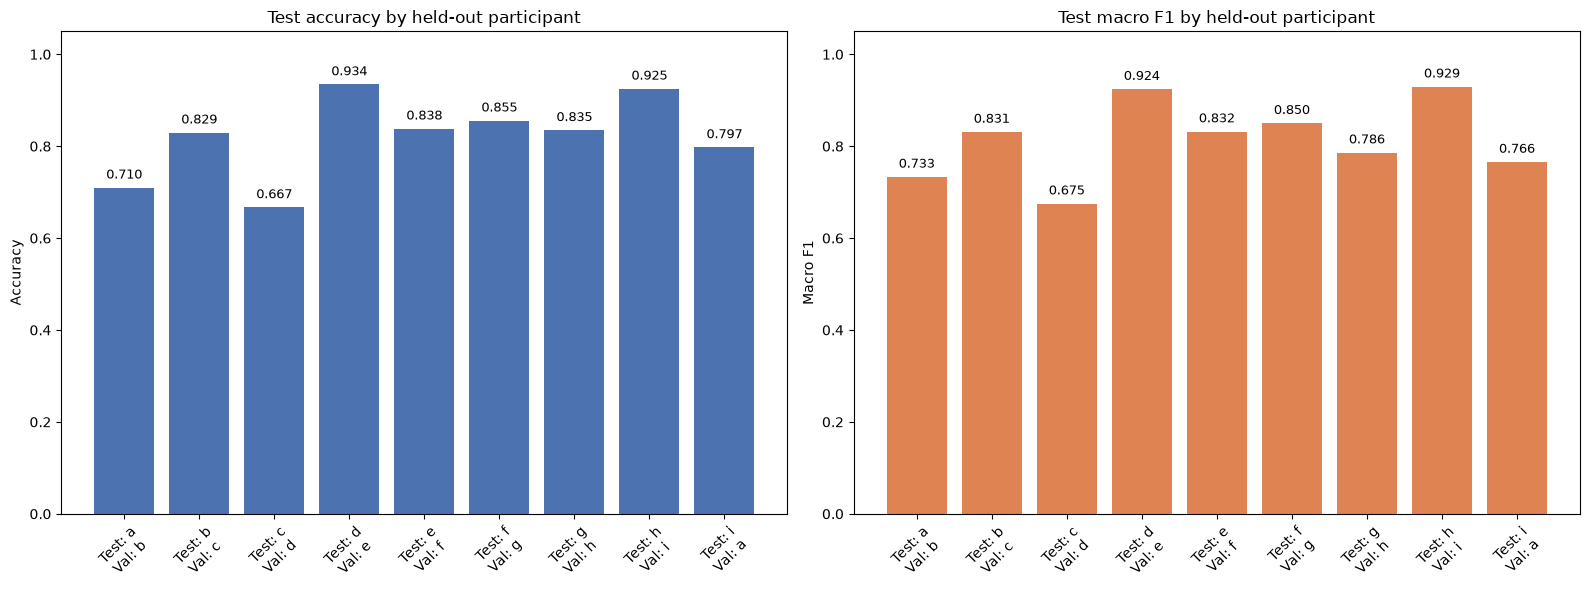

In [11]:
# Create a table with one row per leave-one-participant-out fold
lopo_table = pd.DataFrame([
    {
        "Test participant": result["test_participant"],
        "Validation participant": result["validation_participant"],
        "Test windows": len(result["test_idx"]),
        "Accuracy": result["accuracy"],
        "Macro F1": result["macro_f1"],
        "Epochs trained": len(result["history"]["loss"])
    }
    for result in lopo_results
])

# Sort by test participant for easier reading
lopo_table = lopo_table.sort_values("Test participant").reset_index(drop=True)

print("Leave-one-participant-out results:\n")
print(lopo_table.to_string(index=False))

print(
    f"\nMean accuracy: {lopo_table['Accuracy'].mean():.4f} "
    f"± {lopo_table['Accuracy'].std():.4f}"
)

print(
    f"Mean macro F1: {lopo_table['Macro F1'].mean():.4f} "
    f"± {lopo_table['Macro F1'].std():.4f}"
)

# Plot accuracy and macro F1 for every held-out test participant
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bar_labels = [
    f"Test: {row['Test participant']}\nVal: {row['Validation participant']}"
    for _, row in lopo_table.iterrows()
]

axes[0].bar(
    bar_labels,
    lopo_table["Accuracy"],
    color="#4C72B0"
)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Test accuracy by held-out participant")
axes[0].tick_params(axis="x", rotation=45)

for index, value in enumerate(lopo_table["Accuracy"]):
    axes[0].text(
        index,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

axes[1].bar(
    bar_labels,
    lopo_table["Macro F1"],
    color="#DD8452"
)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Macro F1")
axes[1].set_title("Test macro F1 by held-out participant")
axes[1].tick_params(axis="x", rotation=45)

for index, value in enumerate(lopo_table["Macro F1"]):
    axes[1].text(
        index,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

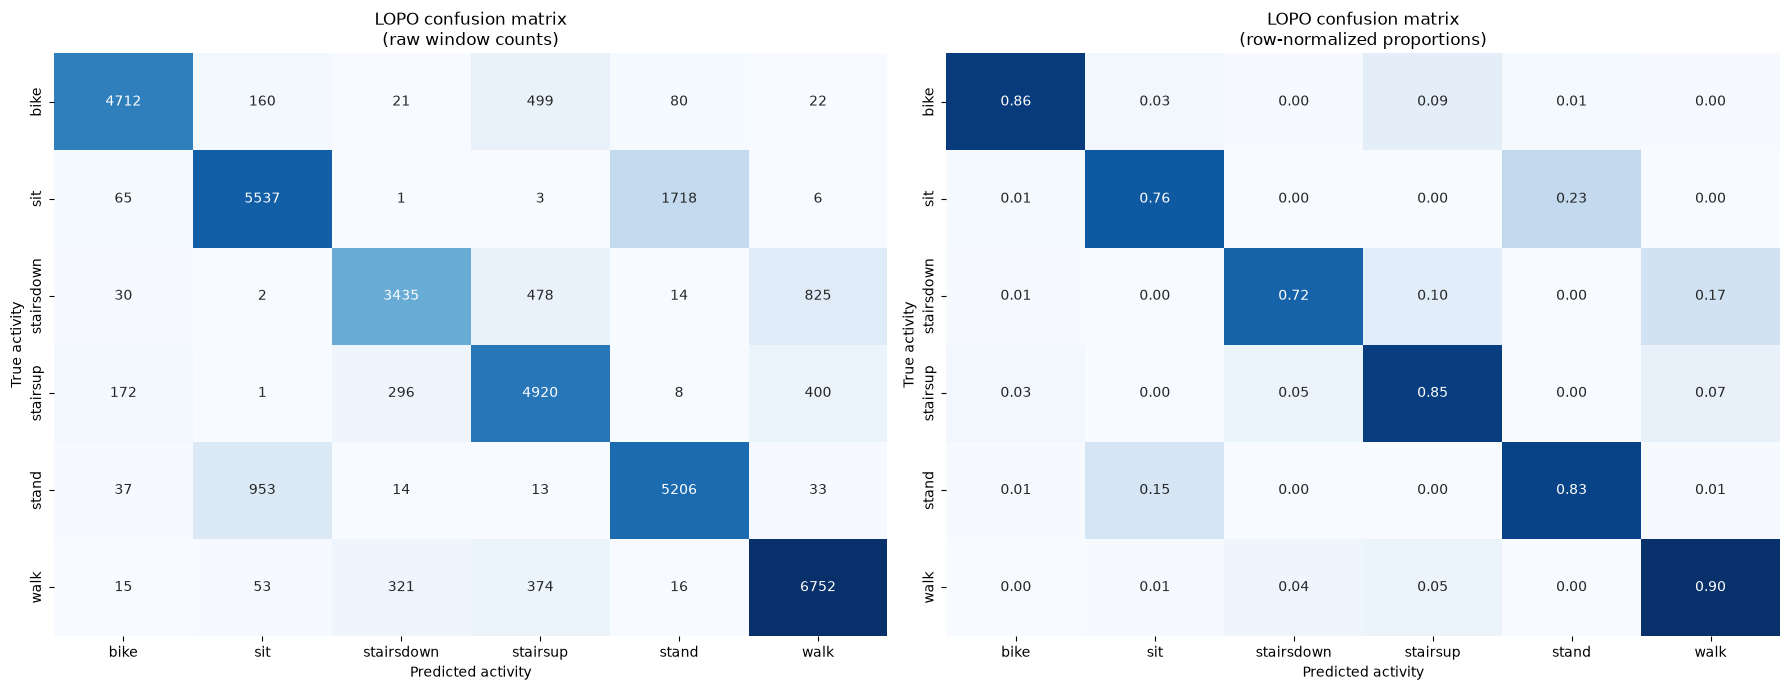

LOPO confusion matrix (rows = true activity, columns = predicted activity):

True\Pred   bike        sit         stairsdown  stairsup    stand       walk        
bike        4712        160         21          499         80          22          
sit         65          5537        1           3           1718        6           
stairsdown  30          2           3435        478         14          825         
stairsup    172         1           296         4920        8           400         
stand       37          953         14          13          5206        33          
walk        15          53          321         374         16          6752        


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Combine predictions and true labels from all nine LOPO folds
all_y_true = np.concatenate([
    result["y_true"]
    for result in lopo_results
])

all_y_pred = np.concatenate([
    result["y_pred"]
    for result in lopo_results
])

# Create the confusion matrix
cm = confusion_matrix(
    all_y_true,
    all_y_pred,
    labels=np.arange(len(class_names))
)

# Normalize by row so each activity sums to 1
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Raw counts
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=False,
    ax=axes[0]
)

axes[0].set_xlabel("Predicted activity")
axes[0].set_ylabel("True activity")
axes[0].set_title("LOPO confusion matrix\n(raw window counts)")

# Row-normalized percentages
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=False,
    ax=axes[1]
)

axes[1].set_xlabel("Predicted activity")
axes[1].set_ylabel("True activity")
axes[1].set_title("LOPO confusion matrix\n(row-normalized proportions)")

plt.tight_layout()
plt.show()

# Print the matrix in text form as well
print("LOPO confusion matrix (rows = true activity, columns = predicted activity):\n")

header = "True\\Pred".ljust(12) + "".join(
    name.ljust(12)
    for name in class_names
)
print(header)

for index, name in enumerate(class_names):
    row = name.ljust(12)

    for column in range(len(class_names)):
        row += str(cm[index, column]).ljust(12)

    print(row)